# R / bnlearn：出力の意味と妥当性を検証する

**実行環境：conda `bn`、カーネル `R (bn)`。分析はRとbnlearnのみで行い、pgmpyは使用しません。**

目的は正解構造や因果関係の証明ではなく、①構造がデータを説明できるか、②確率を十分な精度で推定できるか、③項目間の関係が取り直しても残るか、を区別して検証することです。

既存の5列の人工データ（Cloudy=曇り、Rain=雨、Sprinkler=散水、WetGrass=芝生の濡れ、Slippery=滑りやすい状態、いずれも0/1）を使います。Slipperyは事故実績ではありません。開発標本2,400行、過去使用済みの評価標本2,000行。新しい独立検証や実業務の成果とは呼びません。

## 結論：数値の種類によって「妥当」の意味が違う

| 指標 | 良い方向／基準点 | どの程度なら妥当か |
|---|---|---|
| bnlearnのBIC・BDeu | **高い**ほど相対的に良い | 絶対的合格点なし。同じ変数・標本・スコア設定で比較し、CVを併用 |
| 全変数の平均負の対数尤度（joint NLL） | **低い**ほど良い | 独立モデルなどの基準より改善。値の絶対水準は変数数・状態数・分布に依存 |
| 目的変数のLog loss | **低い**ほど良い、0は完全予測 | 発生率だけの基準との改善幅を評価。実務上の最小差は業務側で設定 |
| Brier score（二値） | **低い**ほど良い、0は完全、範囲0〜1 | 0.25は常に0.5を予測した場合の値で、一般的な合格境界ではない |
| Brier skill | **高い**ほど良い、0は基準同等、1は完全 | >0は指定した基準より良いだけで実用性の保証ではない |
| CPTの確率 | 高い／低い自体に良し悪しなし | 0〜1・和1が必須。件数と区間幅、予測性能、事前感度を確認 |
| CPTの事後区間幅 | 同条件なら**狭い**ほど精密 | 本例の幅0.20は暫定設定。求める判断精度から設定し直す |
| Bootstrap strength | **高い**ほど再出現が安定 | 公式の一律合格点なし。自動境界、0.70/0.85/0.95、乱数・手法間で確認 |
| direction | 0.5から離れるほど一方向の支持 | 0.5は方向不確定。1が「ネットワークとして良い」わけではない |
| 辺削除時のΔBIC | **より負**なら辺のスコア寄与が大きい | 0は改善なし。負だから必ず重要とはせず、再標本化と併用 |
| 相互情報量・CramérのV | **高い**ほど関連が大きい | 普遍的な弱／中／強の境界を設定しない。尺度・分布・目的に依存 |
| 多重性調整済みp値 | **小さい**ほど独立仮説に反する証拠 | 0.05は慣用水準で、効果の大きさや実務妥当性の合格点ではない |

**「数学的な必須条件」「公式実装の仕様」「本例の暫定設定」を分けます。** 妥当性を一つの数値で自動合格にしません。各節のMarkdownには出典・出力列の意味・判断例・繰り返しの必要性を記載しています。


## 1. 環境・設定・データ品質

### 出力の意味
`state1/state0`は状態別の件数、missingは欠損数です。少ない状態や親の組合せがあると推定が不安定になります。現在のプログラムは欠損なしの二値データ用です。実データの欠損を0に置き換えず、別途処理方針を決めてください。

### 設定と判断
CVは5分割×10回、Bootstrapは各手法1,000回×3seed。CPTの信用区間幅0.20、Monte Carlo半幅0.02は**説明用の設定**で、公的な合格基準ではありません。設定は最初のCONFIGで変更可能です。実業務の最小改善幅は設定していないため採用可否は保留します。重複する0/1の組合せは別の観測として起こるので自動削除しません。独立行の仮定は実データで別途確認してください。

In [11]:
library(bnlearn)
stopifnot(grepl('/envs/bn/',R.home(),fixed=TRUE))
options(repr.plot.width=14,repr.plot.height=5)
CONFIG<-list(cv_runs=10,cv_folds=5,bootstrap_R=1000,bootstrap_seeds=c(101,202,303),candidate_thresholds=c(.70,.85,.95),probability_width=.20,mc_halfwidth=.02,split_seed=42)
set.seed(CONFIG$split_seed)
read_data<-function(p){d<-read.csv(p);stopifnot(!anyNA(d),all(vapply(d,function(x)all(x %in% c(0,1)),logical(1))));d[]<-lapply(d,factor,levels=c(0,1));d}
dev<-read_data('data/develop.csv');evaluation<-read_data('data/validation.csv');target<-'Slippery'
md_table<-function(d){x<-d;for(k in names(x))if(is.numeric(x[[k]]))x[[k]]<-formatC(x[[k]],digits=4,format='f');paste(c(paste0('| ',paste(names(x),collapse=' | '),' |'),paste0('| ',paste(rep('---',ncol(x)),collapse=' | '),' |'),apply(x,1,function(r)paste0('| ',paste(r,collapse=' | '),' |'))),collapse='\n')}
show<-function(title,d,note=''){write.csv(d,paste0('results/',title,'.csv'),row.names=FALSE);IRdisplay::display_markdown(paste0('### ',title,'\n\n',md_table(d),'\n\n',note))}
quality<-data.frame(variable=names(dev),n=nrow(dev),missing=sapply(dev,function(x)sum(is.na(x))),state1=sapply(dev,function(x)sum(x=='1')),state0=sapply(dev,function(x)sum(x=='0')))
show('data_quality',quality);print(CONFIG);print(R.version.string);print(packageVersion('bnlearn'))

### data_quality

| variable | n | missing | state1 | state0 |
| --- | --- | --- | --- | --- |
| Cloudy | 2400.0000 | 0.0000 | 1215.0000 | 1185.0000 |
| Rain | 2400.0000 | 0.0000 | 1182.0000 | 1218.0000 |
| Sprinkler | 2400.0000 | 0.0000 | 724.0000 | 1676.0000 |
| WetGrass | 2400.0000 | 0.0000 | 1529.0000 | 871.0000 |
| Slippery | 2400.0000 | 0.0000 | 1400.0000 | 1000.0000 |



$cv_runs
[1] 10

$cv_folds
[1] 5

$bootstrap_R
[1] 1000

$bootstrap_seeds
[1] 101 202 303

$candidate_thresholds
[1] 0.70 0.85 0.95

$probability_width
[1] 0.2

$mc_halfwidth
[1] 0.02

$split_seed
[1] 42

[1] "R version 4.5.3 (2026-03-11)"
[1] ‘5.2.1’


## 2. 確率評価の関数と数学的な検査

### 確率計算は何を確認するか
bnlearnのCPTから全32状態の同時確率を計算し、周辺化します。これは5二値変数に適した厳密計算です。変数を増やすと2^pに増大するため大規模データでは別の推論法が必要です。

- `joint_NLL`：全5項目を同時に観測した確率の−logを1行で平均したもの。正の値が小さいほど予測分布が実績に近い。
- `target_NLL`：残り4項目を知ったときのSlipperyの予測損失。joint_NLLと数値を直接比較しません。
- `Brier`：予測確率と0/1実績の差の二乗平均。
- `valid_CPT`：有限値、0〜1、各親状態の確率和1を点検。

不可能だと予測した事象が実際に出たとき、対数損失は∞になります。小さな値への置換で隠しません。参考：[bnlearnパラメータ推定](https://www.bnlearn.com/examples/fit/)、[確率評価と校正](https://scikit-learn.org/stable/modules/calibration.html)。後者は指標の解説資料として参照するだけで、Pythonのライブラリは実行しません。

In [12]:
joint<-function(f){g<-expand.grid(setNames(rep(list(c('0','1')),length(f)),names(f)),stringsAsFactors=FALSE);p<-rep(1,nrow(g));for(v in names(f)){tab<-f[[v]]$prob;vs<-names(dimnames(tab));if(is.null(vs))vs<-v;p<-p*vapply(seq_len(nrow(g)),function(i)do.call('[',c(list(tab),as.list(g[i,vs,drop=FALSE]),list(drop=TRUE))),numeric(1))};stopifnot(all(is.finite(p)),abs(sum(p)-1)<1e-8);g$prob<-p;g}
query<-function(j,evidence=list()){ix<-rep(TRUE,nrow(j));for(v in names(evidence))ix<-ix & j[[v]]==as.character(evidence[[v]]);sum(j$prob[ix & j[[target]]=='1'])/sum(j$prob[ix])}
pred<-function(f,d){j<-joint(f);fs<-setdiff(names(f),target);keys<-apply(d[,fs,drop=FALSE],1,paste,collapse='|');u<-which(!duplicated(keys));values<-vapply(u,function(i)query(j,as.list(d[i,fs,drop=FALSE])),numeric(1));unname(setNames(values,keys[u])[keys])}
binary_loss<-function(y,p){out<-numeric(length(y));out[y==1]<- -log(p[y==1]);out[y==0]<- -log1p(-p[y==0]);out}
learn<-function(d,a)switch(a,HC_BIC=hc(d,score='bic',maxp=3),HC_BDeu=hc(d,score='bde',iss=10,maxp=3),Tabu=tabu(d,score='bic',maxp=3),MMHC=mmhc(d,restrict.args=list(test='mi',alpha=.01),maximize.args=list(score='bic',maxp=3)),Independent=empty.graph(names(d)))
fit_model<-function(g,d,method){if(method=='MLE')bn.fit(g,d,method='mle')else bn.fit(g,d,method='bayes',iss=as.numeric(sub('Bayes','',method)))}
valid_fit<-function(f)all(vapply(f,function(node){p<-node$prob;all(is.finite(p))&&all(p>=0)&&all(p<=1)&&all(abs(colSums(matrix(p,nrow=dim(p)[1]))-1)<1e-8)},logical(1)))
assess<-function(f,d){if(!valid_fit(f))return(c(joint_NLL=NA,target_NLL=NA,Brier=NA));p<-pred(f,d);y<-as.numeric(d[[target]]=='1');c(joint_NLL=-as.numeric(logLik(f,data=d))/nrow(d),target_NLL=mean(binary_loss(y,p)),Brier=mean((y-p)^2))}

## 3. 構造学習スコアの比較

### BICの符号に注意
bnlearnは `logLik − (log(n)/2)×自由パラメータ数` を返すため**高い方が良い**。一般の `−2logLik + log(n)×自由パラメータ数` とは−2倍の関係です。`BIC_bnlearn=-5000` と `-5100`なら前者が候補中では良い。

`gap_from_best_BIC`は最大BICとの差なので0が最良。`conventional_delta_BIC`はその2倍。同値な構造が同点になることがあり、最高点を得ても唯一の正しい構造とは言えません。BDeuの値はISSにも依存するため異なるISSでの差を同じ物差しとみなしません。訓練スコアだけで妥当性を確定せず次節の再標本化評価を使います。

**一律の合格値はありません。** 辺数も少ないほど常に良いわけではなく、適合と複雑さの兼ね合いです。出典：[bnlearn scoreの定義](https://www.bnlearn.com/documentation/man/score.html)。

In [13]:
algorithms<-c('HC_BIC','HC_BDeu','Tabu','MMHC','Independent')
nets<-setNames(lapply(algorithms,function(a)learn(dev,a)),algorithms)
scores<-do.call(rbind,lapply(algorithms,function(a){g<-nets[[a]];data.frame(algorithm=a,edges=nrow(arcs(g)),parameters=nparams(g,dev),BIC_bnlearn=score(g,dev,type='bic'),BDeu=score(g,dev,type='bde',iss=10))}))
scores$gap_from_best_BIC<-max(scores$BIC_bnlearn)-scores$BIC_bnlearn
scores$conventional_delta_BIC<-2*scores$gap_from_best_BIC
show('structure_scores',scores,'同じデータ・変数で比較。gap=0が候補中の最高。差が0でも唯一の構造とは限りません。常用BICの差はbnlearnの差の2倍です。')

### structure_scores

| algorithm | edges | parameters | BIC_bnlearn | BDeu | gap_from_best_BIC | conventional_delta_BIC |
| --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| HC_BDeu | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| Tabu | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| MMHC | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| Independent | 0.0000 | 5.0000 | -8017.8055 | -8013.4292 | 2286.3437 | 4572.6875 |

同じデータ・変数で比較。gap=0が候補中の最高。差が0でも唯一の構造とは限りません。常用BICの差はbnlearnの差の2倍です。

## 4. 同じ分割での反復交差検証：構造とパラメータを検証

### なぜ繰り返すのか
1回だけでは分割が有利だった可能性が残るため、**5分割を10回**繰り返します。構造選択も各訓練fold内でやり直します。比較する手法は同じ分割を使います。HC/Tabu/MMHC等の構造比較はBayes10で統一し、パラメータ比較はHC_BICの同じfold内構造でMLE・ISS=1/10/100を比べます。

### 出力からの判断
`joint_NLL_mean`が低いモデルを候補としますが、同じ標本を使うrun間は独立ではありません。`min/max`は分割による範囲であり信頼区間ではなく、10回を独立サンプルとしたt検定もしません。`positive_run_fraction=1`は10回すべてで基準より良かったという記述にとどまります。

分割範囲が大きい／順位が変わる場合は20〜50回などに増やして安定を確認する方法がありますが、これは実務上の運用例で公式推奨回数ではありません。繰り返しで情報そのものは増えません。時系列・施設別データならその単位で分割してください。多数の候補から最良を選んで性能を主張する場合はネストしたCVか未使用の評価標本が別途必要です。

参考：[bnlearnのCV仕様](https://www.bnlearn.com/documentation/man/bn.cv.html)。今回は各候補を同じ分割で評価できるようRでループを書き、学習にはbnlearnを使っています。

In [14]:
specs<-rbind(data.frame(algorithm=algorithms,method='Bayes10'),data.frame(algorithm='HC_BIC',method=c('MLE','Bayes1','Bayes100')))
cv<-list();runs<-CONFIG$cv_runs;k<-CONFIG$cv_folds
for(run in seq_len(runs)){
 set.seed(500+run);fold<-integer(nrow(dev));for(z in levels(dev[[target]])){ix<-which(dev[[target]]==z);fold[ix]<-sample(rep(seq_len(k),length.out=length(ix)))}
 for(b in seq_len(k)){
  tr<-dev[fold!=b,];te<-dev[fold==b,];gg<-setNames(lapply(algorithms,function(a)learn(tr,a)),algorithms)
  for(i in seq_len(nrow(specs))){a<-specs$algorithm[i];m<-specs$method[i];f<-fit_model(gg[[a]],tr,m);sc<-assess(f,te);cv[[length(cv)+1]]<-data.frame(run=run,fold=b,n=nrow(te),algorithm=a,method=m,t(sc),valid_CPT=valid_fit(f))}
 }
 cat('CV run',run,'of',runs,'\n')
}
cv<-do.call(rbind,cv);write.csv(cv,'results/cv_all_folds.csv',row.names=FALSE)
run_scores<-aggregate(cbind(joint_NLL,target_NLL,Brier)~run+algorithm+method,data=cv,FUN=mean,na.action=na.pass)
cv_summary<-do.call(rbind,lapply(split(run_scores,interaction(run_scores$algorithm,run_scores$method,drop=TRUE)),function(x)data.frame(algorithm=x$algorithm[1],method=x$method[1],runs=nrow(x),joint_NLL_mean=mean(x$joint_NLL),joint_NLL_min=min(x$joint_NLL),joint_NLL_max=max(x$joint_NLL),target_NLL=mean(x$target_NLL),Brier=mean(x$Brier))))
show('repeated_CV',cv_summary,'低いほど良好。min/maxは分割を変えた10回の観測範囲で、95%信頼区間ではありません。各foldで構造から学習しています。MLEの無限大損失やNAは除外せず保存します。')
base<-run_scores[run_scores$algorithm=='Independent',c('run','joint_NLL')];names(base)[2]<-'baseline'
gain<-merge(run_scores,base,by='run');gain$improvement<-gain$baseline-gain$joint_NLL
stability_cv<-do.call(rbind,lapply(split(gain,interaction(gain$algorithm,gain$method,drop=TRUE)),function(x)data.frame(algorithm=x$algorithm[1],method=x$method[1],mean_improvement=mean(x$improvement),positive_run_fraction=mean(x$improvement>0))))
show('CV_improvement',stability_cv,'改善幅>0なら独立モデルより良好。10/10で改善しても確率100%の保証ではありません。繰り返しは同じ標本を共有するため独立試験ではありません。')

CV run 1 of 10 
CV run 2 of 10 
CV run 3 of 10 
CV run 4 of 10 
CV run 5 of 10 
CV run 6 of 10 
CV run 7 of 10 
CV run 8 of 10 
CV run 9 of 10 
CV run 10 of 10 


### repeated_CV

| algorithm | method | runs | joint_NLL_mean | joint_NLL_min | joint_NLL_max | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | Bayes1 | 10.0000 | 2.3754 | 2.3732 | 2.3767 | 0.3830 | 0.1120 |
| HC_BDeu | Bayes10 | 10.0000 | 2.3753 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| HC_BIC | Bayes10 | 10.0000 | 2.3753 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| Independent | Bayes10 | 10.0000 | 3.3339 | 3.3331 | 3.3347 | 0.6792 | 0.2431 |
| MMHC | Bayes10 | 10.0000 | 2.3774 | 2.3733 | 2.3974 | 0.3830 | 0.1120 |
| Tabu | Bayes10 | 10.0000 | 2.3752 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| HC_BIC | Bayes100 | 10.0000 | 2.3821 | 2.3804 | 2.3834 | 0.3845 | 0.1123 |
| HC_BIC | MLE | 10.0000 | 2.3754 | 2.3733 | 2.3768 | 0.3830 | 0.1120 |

低いほど良好。min/maxは分割を変えた10回の観測範囲で、95%信頼区間ではありません。各foldで構造から学習しています。MLEの無限大損失やNAは除外せず保存します。

### CV_improvement

| algorithm | method | mean_improvement | positive_run_fraction |
| --- | --- | --- | --- |
| HC_BIC | Bayes1 | 0.9586 | 1.0000 |
| HC_BDeu | Bayes10 | 0.9587 | 1.0000 |
| HC_BIC | Bayes10 | 0.9587 | 1.0000 |
| Independent | Bayes10 | 0.0000 | 0.0000 |
| MMHC | Bayes10 | 0.9566 | 1.0000 |
| Tabu | Bayes10 | 0.9588 | 1.0000 |
| HC_BIC | Bayes100 | 0.9519 | 1.0000 |
| HC_BIC | MLE | 0.9585 | 1.0000 |

改善幅>0なら独立モデルより良好。10/10で改善しても確率100%の保証ではありません。繰り返しは同じ標本を共有するため独立試験ではありません。

## 5. パラメータの妥当性：CPTの件数・事後区間・正規化

### CPTは何を意味するか
各行は `P(variable=1 | parentsの状態)`。`n_context`はその親状態の実測件数、eventsはそのうちvariable=1の件数。`MLE=events/n_context`。ベイズ推定は一様Dirichlet事前分布を加えます。親の組合せ数q、二値r=2なら各セルの事前量はISS/(2q)。ISSはノード全体の等価標本数で、各親状態に10件ずつ追加する意味ではありません。

### 妥当性の目安
確率が0.9だから良い／0.1だから悪い、ではありません。件数、予測性能、区間で確認します。`low/high`は**学習した構造を固定した**95%事後信用区間。構造選択・対象者の偏り・モデルの誤りは含みません。幅0.20は約±10ポイントの精度を求める今回の仮設定です。業務で±2ポイントが必要なら幅0.04等を検討します。

件数30や100だけで一律合格にしません。参考として二項比率p=0.5の正規近似では、95%半幅±0.10に約97件、±0.05に約385件が必要ですが、これは各親状態ごとの独立観測数の目安で、CPTの普遍的閾値ではありません。稀少事象では近似が悪いため実際の区間を確認します。

`n_context=0`はデータ根拠なし。ベイズ推定で数値を出せても事前分布頼みです。固定構造の解析的信用区間は反復不要。構造選択まで含めたい場合は構造からの再学習が必要です。参考：[bnlearnの推定例](https://www.bnlearn.com/examples/fit/)、[NIST：比率の区間](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm)。

In [15]:
chosen<-nets$HC_BIC;fitted<-fit_model(chosen,dev,'Bayes10');iss<-10
cpt<-list()
for(v in names(fitted)){
 pa<-parents(chosen,v);contexts<-if(length(pa))expand.grid(setNames(lapply(pa,function(p)levels(dev[[p]])),pa),stringsAsFactors=FALSE)else data.frame(dummy=1)
 q<-nrow(contexts)
 for(i in seq_len(q)){
  ix<-rep(TRUE,nrow(dev));if(length(pa))for(p in pa)ix<-ix & dev[[p]]==contexts[[p]][i]
  n<-sum(ix);yes<-sum(dev[[v]][ix]=='1');alpha<-iss/(2*q);post<-(yes+alpha)/(n+2*alpha)
  tab<-fitted[[v]]$prob;vs<-names(dimnames(tab));if(is.null(vs))vs<-v
  vals<-setNames(list('1'),v);for(p in pa)vals[[p]]<-contexts[[p]][i]
  actual<-do.call('[',c(list(tab),vals[vs],list(drop=TRUE)));stopifnot(abs(actual-post)<1e-10)
  lo<-qbeta(.025,yes+alpha,n-yes+alpha);hi<-qbeta(.975,yes+alpha,n-yes+alpha)
  cpt[[length(cpt)+1]]<-data.frame(variable=v,parents=if(length(pa))paste(paste(pa,contexts[i,pa],sep='='),collapse=',')else '(none)',n_context=n,events=yes,MLE=if(n)yes/n else NA,Bayes10=post,low=lo,high=hi,width=hi-lo,precision_check=if(hi-lo<=CONFIG$probability_width)'within_demo_tolerance'else 'needs_more_data')
 }
}
cpt<-do.call(rbind,cpt);show('CPT_precision',cpt,'low/highは構造とISSを固定したBeta事後95%信用区間。構造選択の不確実性は含みません。幅0.20は今回の仮の許容値であり公式合格基準ではありません。n_context=0ならデータ根拠がありません。')
checks<-do.call(rbind,lapply(c('MLE','Bayes1','Bayes10','Bayes100'),function(m){f<-fit_model(chosen,dev,m);data.frame(method=m,valid_CPT=valid_fit(f),zero_probabilities=sum(vapply(f,function(x)sum(x$prob==0,na.rm=TRUE),integer(1))),t(assess(f,evaluation)))}))
show('parameter_checks',checks,'確率は0〜1、親状態ごとの和=1が必須。計算誤差の許容1e-8は数値検査です。MLEで0になる場合、評価でその事象が出ると損失は無限大。ベイズ推定の非ゼロは十分なデータの証拠ではありません。')
prior_detail<-do.call(rbind,lapply(c(1,10,100),function(s){ff<-bn.fit(chosen,dev,method='bayes',iss=s);diff<-unlist(lapply(names(ff),function(v)as.numeric(ff[[v]]$prob)-as.numeric(fitted[[v]]$prob)));data.frame(ISS=s,max_CPT_change_from_ISS10=max(abs(diff)),mean_CPT_change=mean(abs(diff)),t(assess(ff,evaluation)))}))
show('prior_sensitivity',prior_detail,'構造を固定してISSだけを変えた検査。確率の変化は0〜1単位（0.01=1ポイント）。変化が小さければこの範囲の事前設定には頑健ですが、構造変更への頑健性を証明するものではありません。')


### CPT_precision

| variable | parents | n_context | events | MLE | Bayes10 | low | high | width | precision_check |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Cloudy | (none) | 2400.0000 | 1215.0000 | 0.5062 | 0.5062 | 0.4863 | 0.5262 | 0.0399 | within_demo_tolerance |
| Rain | Cloudy=0 | 1185.0000 | 209.0000 | 0.1764 | 0.1777 | 0.1565 | 0.1999 | 0.0434 | within_demo_tolerance |
| Rain | Cloudy=1 | 1215.0000 | 973.0000 | 0.8008 | 0.7996 | 0.7767 | 0.8216 | 0.0449 | within_demo_tolerance |
| Sprinkler | Cloudy=0 | 1185.0000 | 612.0000 | 0.5165 | 0.5164 | 0.4880 | 0.5447 | 0.0568 | within_demo_tolerance |
| Sprinkler | Cloudy=1 | 1215.0000 | 112.0000 | 0.0922 | 0.0939 | 0.0781 | 0.1108 | 0.0327 | within_demo_tolerance |
| WetGrass | Rain=0,Sprinkler=0 | 695.0000 | 36.0000 | 0.0518 | 0.0534 | 0.0380 | 0.0713 | 0.0333 | within_demo_tolerance |
| WetGrass | Rain=1,Sprinkler=0 | 981.0000 | 879.0000 | 0.8960 | 0.8950 | 0.8751 | 0.9134 | 0.0383 | within_demo_tolerance |
| WetGrass | Rain=0,Sprinkler=1 | 523.0000 | 418.0000 | 0.7992 | 0.7978 | 0.7625 | 0.8310 | 0.0686 | within_demo_tolerance |
| WetGrass | Rain=1,Sprinkler=1 | 201.0000 | 196.0000 | 0.9751 | 0.9693 | 0.9416 | 0.9883 | 0.0467 | within_demo_tolerance |
| Slippery | WetGrass=0 | 871.0000 | 90.0000 | 0.1033 | 0.1056 | 0.0861 | 0.1268 | 0.0406 | within_demo_tolerance |
| Slippery | WetGrass=1 | 1529.0000 | 1310.0000 | 0.8568 | 0.8556 | 0.8376 | 0.8727 | 0.0352 | within_demo_tolerance |

low/highは構造とISSを固定したBeta事後95%信用区間。構造選択の不確実性は含みません。幅0.20は今回の仮の許容値であり公式合格基準ではありません。n_context=0ならデータ根拠がありません。

### parameter_checks

| method | valid_CPT | zero_probabilities | joint_NLL | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- |
| MLE | TRUE | 0.0000 | 2.3784 | 0.3999 | 0.1186 |
| Bayes1 | TRUE | 0.0000 | 2.3785 | 0.3999 | 0.1186 |
| Bayes10 | TRUE | 0.0000 | 2.3789 | 0.3998 | 0.1186 |
| Bayes100 | TRUE | 0.0000 | 2.3860 | 0.3999 | 0.1186 |

確率は0〜1、親状態ごとの和=1が必須。計算誤差の許容1e-8は数値検査です。MLEで0になる場合、評価でその事象が出ると損失は無限大。ベイズ推定の非ゼロは十分なデータの証拠ではありません。

### prior_sensitivity

| ISS | max_CPT_change_from_ISS10 | mean_CPT_change | joint_NLL | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- |
| 1.0000 | 0.0052 | 0.0014 | 2.3785 | 0.3999 | 0.1186 |
| 10.0000 | 0.0000 | 0.0000 | 2.3789 | 0.3998 | 0.1186 |
| 100.0000 | 0.0467 | 0.0135 | 2.3860 | 0.3999 | 0.1186 |

構造を固定してISSだけを変えた検査。確率の変化は0〜1単位（0.01=1ポイント）。変化が小さければこの範囲の事前設定には頑健ですが、構造変更への頑健性を証明するものではありません。

## 6. 関係の安定性：3つの乱数 × 各1000回 × 2手法

### strengthとdirectionを混同しない
strengthは同じサイズの標本を復元抽出して構造を再学習したとき、向きを無視した辺が出た割合です。directionは辺が存在する条件で表のfrom→toを支持する割合。CPDAGに変換するため同値な向きの不確実性を含みます。strength=0ならdirectionは定義できないためNAです。

### どの程度なら採用候補か
公式の一律基準はありません。`inclusion.threshold()`によるデータ依存の境界を併記し、0.70/0.85/0.95を超える辺がどう変わるかを示します。**0.85は便宜的な確認値で、有意水準15%でも真実確率85%でもありません。** 自動境界もFDRを保証しません。

1,000回を3つのseedで繰り返し、各手法3,000回分を集計します。`seed_range`は乱数別強度の最大−最小。HCとTabuで大きく違えば手法依存として保留します。`MC_low/high`は固定データに対する計算上の出現割合のWilson区間。母集団の辺が正しい確率ではありません。`robust_to_MC`はこの区間下限が指定境界を超えることだけを表します。

出典：[bnlearn アーク強度・自動閾値](https://www.bnlearn.com/documentation/man/arc.strength.html)、[NIST Wilson区間](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm)。

In [16]:
boots<-list();bootstrap_long<-list();thresholds<-list()
for(a in c('hc','tabu'))for(seed in CONFIG$bootstrap_seeds){
 set.seed(seed);b<-boot.strength(dev,R=CONFIG$bootstrap_R,algorithm=a,algorithm.args=list(score='bic',maxp=3),cpdag=TRUE)
 key<-paste(a,seed,sep='_');boots[[key]]<-b;z<-as.data.frame(b[b$from<b$to,]);z$algorithm<-a;z$seed<-seed;bootstrap_long[[key]]<-z
 thresholds[[key]]<-data.frame(algorithm=a,seed=seed,automatic_threshold=inclusion.threshold(b));cat('Bootstrap',key,'done\n')
}
bootstrap_long<-do.call(rbind,bootstrap_long);write.csv(bootstrap_long,'results/bootstrap_by_seed.csv',row.names=FALSE)
show('automatic_thresholds',do.call(rbind,thresholds),'inclusion.thresholdはデータから算出される境界で、FDR5%の保証や真の関係の確率ではありません。境界と同じ強度の辺は採用条件strength > thresholdを満たしません。')
edges<-do.call(rbind,lapply(split(bootstrap_long,interaction(bootstrap_long$algorithm,bootstrap_long$from,bootstrap_long$to,drop=TRUE)),function(z){p<-mean(z$strength);N<-CONFIG$bootstrap_R*nrow(z);zz<-1.96;center<-(p+zz^2/(2*N))/(1+zz^2/N);half<-zz*sqrt(p*(1-p)/N+zz^2/(4*N*N))/(1+zz^2/N);data.frame(algorithm=z$algorithm[1],from=z$from[1],to=z$to[1],strength=p,seed_range=diff(range(z$strength)),MC_low=center-half,MC_high=center+half,direction=if(sum(z$strength)>0)weighted.mean(z$direction,z$strength)else NA,MC_halfwidth=half)}))
show('edge_stability',edges,'MC区間は固定された入力標本からの反復回数の有限性だけを表します。母集団の真の辺への信頼区間ではありません。directionはこの表のfrom→toを支持する度合いで、0.5付近は方向不確定。')
threshold_sensitivity<-do.call(rbind,lapply(CONFIG$candidate_thresholds,function(t){x<-edges;x$threshold<-t;x$selected<-x$strength>t;x$robust_to_MC<-x$MC_low>t;x[,c('algorithm','from','to','threshold','strength','selected','robust_to_MC')]}))
show('threshold_sensitivity',threshold_sensitivity,'0.70/0.85/0.95は感度を見るための例示的境界です。0.85を普遍的な妥当性基準にはしません。MC下限が閾値を超える場合でも実務的重要性を意味しません。')

Bootstrap hc_101 done
Bootstrap hc_202 done
Bootstrap hc_303 done
Bootstrap tabu_101 done
Bootstrap tabu_202 done
Bootstrap tabu_303 done


### automatic_thresholds

| algorithm | seed | automatic_threshold |
| --- | --- | --- |
| hc | 101.0000 | 0.6370 |
| hc | 202.0000 | 0.6470 |
| hc | 303.0000 | 0.2860 |
| tabu | 101.0000 | 1.0000 |
| tabu | 202.0000 | 0.1290 |
| tabu | 303.0000 | 1.0000 |

inclusion.thresholdはデータから算出される境界で、FDR5%の保証や真の関係の確率ではありません。境界と同じ強度の辺は採用条件strength > thresholdを満たしません。

### edge_stability

| algorithm | from | to | strength | seed_range | MC_low | MC_high | direction | MC_halfwidth |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| hc | Cloudy | Rain | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4995 | 0.0006 |
| tabu | Cloudy | Rain | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4997 | 0.0006 |
| hc | Cloudy | Slippery | 0.0010 | 0.0020 | 0.0003 | 0.0029 | 0.8333 | 0.0013 |
| tabu | Cloudy | Slippery | 0.0017 | 0.0030 | 0.0007 | 0.0039 | 0.9000 | 0.0016 |
| hc | Rain | Slippery | 0.0030 | 0.0020 | 0.0016 | 0.0057 | 0.5556 | 0.0021 |
| tabu | Rain | Slippery | 0.0050 | 0.0030 | 0.0030 | 0.0082 | 0.9000 | 0.0026 |
| hc | Cloudy | Sprinkler | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4995 | 0.0006 |
| tabu | Cloudy | Sprinkler | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4997 | 0.0006 |
| hc | Rain | Sprinkler | 0.6457 | 0.0160 | 0.6284 | 0.6626 | 0.4987 | 0.0171 |
| tabu | Rain | Sprinkler | 0.1270 | 0.0060 | 0.1156 | 0.1394 | 0.5000 | 0.0119 |
| hc | Slippery | Sprinkler | 0.0047 | 0.0040 | 0.0028 | 0.0078 | 0.3929 | 0.0025 |
| tabu | Slippery | Sprinkler | 0.0067 | 0.0040 | 0.0043 | 0.0103 | 0.1250 | 0.0030 |
| hc | Cloudy | WetGrass | 0.2727 | 0.0270 | 0.2570 | 0.2889 | 0.5000 | 0.0159 |
| tabu | Cloudy | WetGrass | 0.0003 | 0.0010 | 0.0001 | 0.0019 | 0.5000 | 0.0009 |
| hc | Rain | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.6763 | 0.0006 |
| tabu | Rain | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.9363 | 0.0006 |
| hc | Slippery | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.3228 | 0.0006 |
| tabu | Slippery | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.0635 | 0.0006 |
| hc | Sprinkler | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.6770 | 0.0006 |
| tabu | Sprinkler | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.9363 | 0.0006 |

MC区間は固定された入力標本からの反復回数の有限性だけを表します。母集団の真の辺への信頼区間ではありません。directionはこの表のfrom→toを支持する度合いで、0.5付近は方向不確定。

### threshold_sensitivity

| algorithm | from | to | threshold | strength | selected | robust_to_MC |
| --- | --- | --- | --- | --- | --- | --- |
| hc | Cloudy | Rain | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Rain | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Slippery | 0.7000 | 0.0010 | FALSE | FALSE |
| tabu | Cloudy | Slippery | 0.7000 | 0.0017 | FALSE | FALSE |
| hc | Rain | Slippery | 0.7000 | 0.0030 | FALSE | FALSE |
| tabu | Rain | Slippery | 0.7000 | 0.0050 | FALSE | FALSE |
| hc | Cloudy | Sprinkler | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Sprinkler | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Rain | Sprinkler | 0.7000 | 0.6457 | FALSE | FALSE |
| tabu | Rain | Sprinkler | 0.7000 | 0.1270 | FALSE | FALSE |
| hc | Slippery | Sprinkler | 0.7000 | 0.0047 | FALSE | FALSE |
| tabu | Slippery | Sprinkler | 0.7000 | 0.0067 | FALSE | FALSE |
| hc | Cloudy | WetGrass | 0.7000 | 0.2727 | FALSE | FALSE |
| tabu | Cloudy | WetGrass | 0.7000 | 0.0003 | FALSE | FALSE |
| hc | Rain | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Rain | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Slippery | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Slippery | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Sprinkler | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Sprinkler | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Rain | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Rain | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Slippery | 0.8500 | 0.0010 | FALSE | FALSE |
| tabu | Cloudy | Slippery | 0.8500 | 0.0017 | FALSE | FALSE |
| hc | Rain | Slippery | 0.8500 | 0.0030 | FALSE | FALSE |
| tabu | Rain | Slippery | 0.8500 | 0.0050 | FALSE | FALSE |
| hc | Cloudy | Sprinkler | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Sprinkler | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Rain | Sprinkler | 0.8500 | 0.6457 | FALSE | FALSE |
| tabu | Rain | Sprinkler | 0.8500 | 0.1270 | FALSE | FALSE |
| hc | Slippery | Sprinkler | 0.8500 | 0.0047 | FALSE | FALSE |
| tabu | Slippery | Sprinkler | 0.8500 | 0.0067 | FALSE | FALSE |
| hc | Cloudy | WetGrass | 0.8500 | 0.2727 | FALSE | FALSE |
| tabu | Cloudy | WetGrass | 0.8500 | 0.0003 | FALSE | FALSE |
| hc | Rain | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Rain | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Slippery | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Slippery | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Sprinkler | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Sprinkler | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Rain | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Rain | 0.9500 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Slippery | 0.9500 | 0.0010 | FALSE | FALSE |
| tabu | Cloudy | Slippery | 0.9500 | 0.0017 | FALSE | FALSE |
| hc | Rain | Slippery | 0.9500 | 0.0030 | FALSE | FALSE |
| tabu | Rain | Slippery | 0.9500 | 0.0050 | FALSE | FALSE |
| hc | Cloudy | Sprinkler | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Sprinkler | 0.9500 | 1.0000 | TRUE | TRUE |
| hc | Rain | Sprinkler | 0.9500 | 0.6457 | FALSE | FALSE |
| tabu | Rain | Sprinkler | 0.9500 | 0.1270 | FALSE | FALSE |
| hc | Slippery | Sprinkler | 0.9500 | 0.0047 | FALSE | FALSE |
| tabu | Slippery | Sprinkler | 0.9500 | 0.0067 | FALSE | FALSE |
| hc | Cloudy | WetGrass | 0.9500 | 0.2727 | FALSE | FALSE |
| tabu | Cloudy | WetGrass | 0.9500 | 0.0003 | FALSE | FALSE |
| hc | Rain | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Rain | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| hc | Slippery | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Slippery | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| hc | Sprinkler | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Sprinkler | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |

0.70/0.85/0.95は感度を見るための例示的境界です。0.85を普遍的な妥当性基準にはしません。MC下限が閾値を超える場合でも実務的重要性を意味しません。

## 7. 繰り返し回数はどの程度必要か

### 何回繰り返すべきか
Bootstrap出現率pのMonte Carlo標準誤差は独立な反復を仮定して `sqrt(p(1-p)/R)`。最大はp=0.5。おおよそR=200で95%半幅±6.9ポイント、R=1,000で±3.1ポイント、R=3,000で±1.8ポイントです。

**境界の付近だけなら追加反復が有効**ですが、ほぼ同じ結果を何度見ても元標本の偏りは消えません。今回の目標半幅±2ポイントは計算精度の暫定設定。2401回程度は近似計算から導く目安で、bnlearn公式の必要回数ではありません。

回数を増やしてもHCとTabuが異なる、対象期間で関係が変わる、希少状態が少ない場合は、手法・データ・仮説を見直します。既定seedを変えて都合のよい回だけを選ばないでください。

In [17]:
repeat_plan<-data.frame(bootstrap_R=c(200,500,1000,3000,10000),worst_MC_SE=sqrt(.25/c(200,500,1000,3000,10000)),approx_95_halfwidth=1.96*sqrt(.25/c(200,500,1000,3000,10000)))
show('repeat_precision',repeat_plan,'p=0.5の最悪条件による近似。例えば半幅±0.02を目標とするなら約2401回が目安です。これは再標本化の計算誤差で、データ不足を繰り返し回数で補えるわけではありません。')
need<-ceiling(.25*(1.96/CONFIG$mc_halfwidth)^2);print(need)
show('repeat_status',data.frame(total_per_algorithm=CONFIG$bootstrap_R*length(CONFIG$bootstrap_seeds),max_MC_halfwidth=max(edges$MC_halfwidth),target_halfwidth=CONFIG$mc_halfwidth,need_more_for_MC=max(edges$MC_halfwidth)>CONFIG$mc_halfwidth),'境界に近い辺は回数追加を検討。乱数間・手法間で判断が変わる辺は保留。繰り返すたびに都合のよい結果を選ぶことはしません。')

### repeat_precision

| bootstrap_R | worst_MC_SE | approx_95_halfwidth |
| --- | --- | --- |
| 200.0000 | 0.0354 | 0.0693 |
| 500.0000 | 0.0224 | 0.0438 |
| 1000.0000 | 0.0158 | 0.0310 |
| 3000.0000 | 0.0091 | 0.0179 |
| 10000.0000 | 0.0050 | 0.0098 |

p=0.5の最悪条件による近似。例えば半幅±0.02を目標とするなら約2401回が目安です。これは再標本化の計算誤差で、データ不足を繰り返し回数で補えるわけではありません。

[1] 2401


### repeat_status

| total_per_algorithm | max_MC_halfwidth | target_halfwidth | need_more_for_MC |
| --- | --- | --- | --- |
| 3000.0000 | 0.0171 | 0.0200 | FALSE |

境界に近い辺は回数追加を検討。乱数間・手法間で判断が変わる辺は保留。繰り返すたびに都合のよい結果を選ぶことはしません。

## 8. 効果の大きさと統計的証拠を区別

### 「強さ」「証拠」「直接の辺」は別の概念
- **MI_bits**：二変数の独立からのずれを情報量で測る。0は独立、上限は各変数のエントロピーに依存し、常に1ではありません（本例の二値では最大1bit）。
- **CramérのV**：0〜1の標準化された関連。高いほど関連が大きいが、0.1/0.3/0.5等をどの業務にも共通する合格境界にしません。
- **p_Holm**：10組の独立性検定の多重性をHolm補正。0.05は慣用的な棄却水準で、効果の大きさや採用可否ではありません。小さいpでも効果は小さくあり得ます。今回の検定は無条件であり、間接的な関連も拾います。
- **BIC_after_minus_before**：ほかの辺を固定して一本だけ削除したときのスコア変化。−100は−1より大きな悪化。単位はスコアで確率差ではありません。

「再出現が安定」「情報量がある」「残りのネットワークに対するスコア寄与がある」を重ねて説明します。どれか一つだけで妥当としません。参考：[アーク削除の定義](https://www.bnlearn.com/documentation/man/arc.strength.html)、[R 多重比較補正](https://search.r-project.org/R/refmans/stats/html/p.adjust.html)。

In [18]:
pairs<-combn(names(dev),2,simplify=FALSE)
association<-do.call(rbind,lapply(pairs,function(pair){tab<-table(dev[[pair[1]]],dev[[pair[2]]]);p<-tab/sum(tab);expected<-outer(rowSums(p),colSums(p));MI<-sum(p[p>0]*log2(p[p>0]/expected[p>0]));chi<-sum((tab-sum(tab)*expected)^2/(sum(tab)*expected));test<-ci.test(pair[1],pair[2],data=dev,test='mi');data.frame(x=pair[1],y=pair[2],MI_bits=MI,Cramers_V=sqrt(chi/(sum(tab)*min(nrow(tab)-1,ncol(tab)-1))),p_value=test$p.value)}))
association$p_Holm<-p.adjust(association$p_value,method='holm');association$screen_p05<-association$p_Holm<.05
show('pairwise_association',association,'全10組を検定してHolm補正。p<0.05は慣用的なスクリーニング水準で、効果が大きい・辺が直接存在する・実務的に有用の意味ではありません。MIとVは無条件の関連であり第三変数の影響を除いていません。')
removal<-as.data.frame(arc.strength(chosen,dev,criterion='bic'));names(removal)[3]<-'BIC_after_minus_before';show('edge_removal',removal,'負なら辺を除くとBICが悪化。より大きな負値は残りの構造を固定したときのスコア寄与が大きいことを示し、確率差や因果効果の単位ではありません。')

### pairwise_association

| x | y | MI_bits | Cramers_V | p_value | p_Holm | screen_p05 |
| --- | --- | --- | --- | --- | --- | --- |
| Cloudy | Rain | 0.3034 | 0.6245 | 0.0000 | 0.0000 | TRUE |
| Cloudy | Sprinkler | 0.1653 | 0.4622 | 0.0000 | 0.0000 | TRUE |
| Cloudy | WetGrass | 0.0387 | 0.2304 | 0.0000 | 0.0000 | TRUE |
| Cloudy | Slippery | 0.0196 | 0.1644 | 0.0000 | 0.0000 | TRUE |
| Rain | Sprinkler | 0.0592 | 0.2825 | 0.0000 | 0.0000 | TRUE |
| Rain | WetGrass | 0.2457 | 0.5581 | 0.0000 | 0.0000 | TRUE |
| Rain | Slippery | 0.1213 | 0.4032 | 0.0000 | 0.0000 | TRUE |
| Sprinkler | WetGrass | 0.0656 | 0.2884 | 0.0000 | 0.0000 | TRUE |
| Sprinkler | Slippery | 0.0299 | 0.2001 | 0.0000 | 0.0000 | TRUE |
| WetGrass | Slippery | 0.4283 | 0.7348 | 0.0000 | 0.0000 | TRUE |

全10組を検定してHolm補正。p<0.05は慣用的なスクリーニング水準で、効果が大きい・辺が直接存在する・実務的に有用の意味ではありません。MIとVは無条件の関連であり第三変数の影響を除いていません。

### edge_removal

| from | to | BIC_after_minus_before |
| --- | --- | --- |
| WetGrass | Slippery | -708.6153 |
| Cloudy | Rain | -500.7637 |
| Rain | WetGrass | -700.6192 |
| Sprinkler | WetGrass | -400.9286 |
| Cloudy | Sprinkler | -271.1390 |

負なら辺を除くとBICが悪化。より大きな負値は残りの構造を固定したときのスコア寄与が大きいことを示し、確率差や因果効果の単位ではありません。

## 9. 実績と予測確率の一致・区間付き比較

### 表示確率をどの程度信頼できるか
calibration表のpredictedはその確率帯の平均予測、observedは実際に1だった割合。absolute_gapは小さい方が一致しています。Wilson区間は観測率の不確実性で、BN推定確率の区間ではありません。1〜2個のビンが合っていても全対象で校正良好とは断定しません。

基準は開発標本の発生率を全件に予測するモデル。Brier skill>0で基準より改善、対数損失改善の区間が0をまたぐなら優越を断定しません。今回は2,000回のペア・ブートストラップを使います。これは学習済みモデルを固定した評価行の変動だけです。顧客や期間が依存する場合は単位を変更します。

**過去使用済み評価標本の探索的な再検証**です。これを見て手法や基準を調整した後、同じ評価標本で性能が上がったと確証的に主張しません。参考：[校正とproper scoring rules](https://scikit-learn.org/stable/modules/calibration.html)。

### calibration

| bin | n | predicted | observed | absolute_gap | Wilson_low | Wilson_high |
| --- | --- | --- | --- | --- | --- | --- |
| 0.1-0.2 | 711.0000 | 0.1056 | 0.1111 | 0.0055 | 0.0901 | 0.1363 |
| 0.8-0.9 | 1289.0000 | 0.8556 | 0.8472 | 0.0084 | 0.8265 | 0.8658 |

gapは小さいほど良好ですが、小標本ビンの見かけの差には注意。±0.05などの許容幅は、意思決定の影響から別途合意が必要です。Wilson区間に予測が入ることだけで校正合格とは判定しません。

### baseline_comparison

| mean | low | high | Brier_BN | Brier_baseline | Brier_skill |
| --- | --- | --- | --- | --- | --- |
| 0.2786 | 0.2497 | 0.3060 | 0.1186 | 0.2427 | 0.5113 |

対数損失改善>0、Brier skill>0なら基準より良好。Brier skill=0は同じ、1は完全予測、負は悪化。区間は固定モデルと独立行を仮定し、評価標本のばらつきだけを表します。実務採用には最小改善幅が必要です。

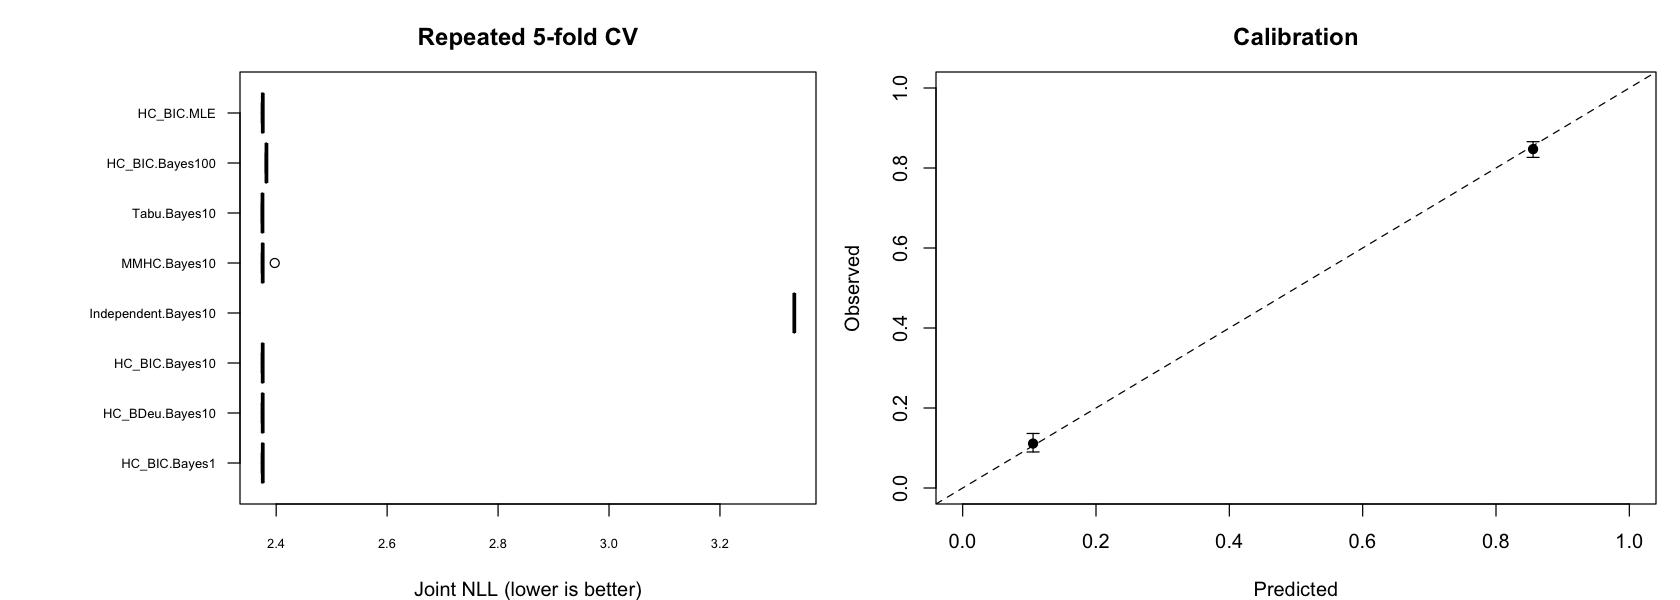

In [19]:
fit<-fit_model(chosen,dev,'Bayes10');p<-pred(fit,evaluation);y<-as.numeric(evaluation[[target]]=='1');baseline<-rep(mean(dev[[target]]=='1'),length(y))
# この5変数を用いた評価は過去使用済み。探索的な再計算として表示。
cal<-do.call(rbind,lapply(0:9,function(b){ix<-p>=b/10 & p<(b+1)/10;N<-sum(ix);if(!N)return(NULL);q<-mean(y[ix]);z<-1.96;mid<-(q+z*z/(2*N))/(1+z*z/N);half<-z*sqrt(q*(1-q)/N+z*z/(4*N*N))/(1+z*z/N);data.frame(bin=paste0(b/10,'-',(b+1)/10),n=N,predicted=mean(p[ix]),observed=q,absolute_gap=abs(q-mean(p[ix])),Wilson_low=mid-half,Wilson_high=mid+half)}))
show('calibration',cal,'gapは小さいほど良好ですが、小標本ビンの見かけの差には注意。±0.05などの許容幅は、意思決定の影響から別途合意が必要です。Wilson区間に予測が入ることだけで校正合格とは判定しません。')
set.seed(900);dif<-binary_loss(y,baseline)-binary_loss(y,p);bs<-replicate(2000,mean(sample(dif,replace=TRUE)));improvement<-data.frame(mean=mean(dif),low=quantile(bs,.025),high=quantile(bs,.975),Brier_BN=mean((y-p)^2),Brier_baseline=mean((y-baseline)^2),Brier_skill=1-mean((y-p)^2)/mean((y-baseline)^2))
show('baseline_comparison',improvement,'対数損失改善>0、Brier skill>0なら基準より良好。Brier skill=0は同じ、1は完全予測、負は悪化。区間は固定モデルと独立行を仮定し、評価標本のばらつきだけを表します。実務採用には最小改善幅が必要です。')
par(bg='white',mfrow=c(1,2),mar=c(4,10,3,1));boxplot(joint_NLL~interaction(algorithm,method,drop=TRUE),data=run_scores,horizontal=TRUE,las=1,cex.axis=.65,ylab='',xlab='Joint NLL (lower is better)',main='Repeated 5-fold CV');par(mar=c(4,4,3,1));plot(cal$predicted,cal$observed,xlim=c(0,1),ylim=c(0,1),xlab='Predicted',ylab='Observed',pch=19,main='Calibration');abline(0,1,lty=2);arrows(cal$predicted,cal$Wilson_low,cal$predicted,cal$Wilson_high,angle=90,code=3,length=.05)

## 10. 判断票：妥当性を単一スコアで決めない

### 実務での最終判断の進め方
1. 数値的整合が崩れていれば利用しない。CPTの和1などは必要条件で十分条件ではない。
2. 構造は訓練スコアだけでなく、繰り返したCVで基準を上回るか確認する。
3. パラメータは親状態ごとの件数・区間幅を確認し、広い箇所の説明を控える。ISSで大きく変わる場合は事前への依存を明記。
4. 辺は複数seed・手法・境界で残るものを安定候補とし、境界付近は保留する。
5. 関連の大きさ、対象範囲、取得時点、誤判定コストから業務上の最小改善を定める。

このNotebookは「計算上・統計上の確認」と「業務で採用して良い」を分けた判断票を出力します。全体の一括合格を自動判定しません。実データでは別期間・別施設での検証が次の段階です。

In [20]:
judgement<-data.frame(check=c('Probability validity','Repeated CV vs independent','CPT precision example','Finite bootstrap precision','Business acceptability'),result=c(if(valid_fit(fit))'passed numerical check'else'failed',paste(sum(stability_cv$positive_run_fraction==1 & stability_cv$algorithm!='Independent'),'configurations improved in every split'),paste(sum(cpt$width>CONFIG$probability_width),'contexts exceed demo width 0.20'),if(max(edges$MC_halfwidth)<=CONFIG$mc_halfwidth)'within configured MC target'else'increase repetitions','not determined: minimum improvement/cost not specified'))
show('validation_decisions',judgement,'統計上の支持・数値的整合・業務上の妥当性は別の判定です。実務採用の自動合格は出しません。')
report<-paste0('# RESULT：R/bnlearnの妥当性検証\n\n',md_table(judgement),'\n\n## 構造比較\n\n',md_table(scores),'\n\n## 反復交差検証\n\n',md_table(cv_summary),'\n\n## パラメータ精度\n\n',md_table(cpt),'\n\n## 関係の安定性\n\n',md_table(edges),'\n\n## 判断上の制約\n\n人工データ・既存評価標本の再利用。構造に正解ラベルを使わない。絶対BIC、出現率0.85、CPT幅0.20などを普遍的合格基準としない。出力の意味と根拠はNotebookのMarkdownセルを参照。')
writeLines(report,'RESULT.md');IRdisplay::display_markdown(report)
saveRDS(list(config=CONFIG,networks=nets,fitted=fit,bootstrap=boots),'results/models_and_settings.rds');capture.output(sessionInfo(),file='results/sessionInfo.txt')
stopifnot(nrow(cv)==CONFIG$cv_runs*CONFIG$cv_folds*nrow(specs),all(cv$valid_CPT),nrow(edges)==20,valid_fit(fit))
cat('All numerical checks passed.\n')
# 今回の数値に基づく読み取りを再実行時に更新する。
hc_edges<-edges[edges$algorithm=='hc',];tabu_edges<-edges[edges$algorithm=='tabu',]
comparison<-merge(hc_edges[,c('from','to','strength')],tabu_edges[,c('from','to','strength')],by=c('from','to'),suffixes=c('_hc','_tabu'))
comparison$algorithm_gap<-abs(comparison$strength_hc-comparison$strength_tabu)
comparison<-comparison[order(-comparison$algorithm_gap),]
show('algorithm_dependence',comparison,'大きな差がある辺はアルゴリズム依存です。反復回数を増やして計算誤差を減らしても、探索法の違いは解消しない場合があります。')
row<-comparison[1,];stable_count<-sum(comparison$strength_hc>.95 & comparison$strength_tabu>.95)
summary_text<-paste0('## 今回の出力をどう読むか\n\n',
'- 両手法で出現率0.95を超える辺は **',stable_count,'本**。この境界は本例の確認値です。\n',
'- 手法差が最も大きい **',row$from,'―',row$to,'** はHC=',round(row$strength_hc*100,1),'%、Tabu=',round(row$strength_tabu*100,1),'%。単一手法だけで安定した関係と断定せず保留します。\n',
'- CPTの95%信用区間幅の最大値は **',round(max(cpt$width)*100,2),'ポイント**。全セルで今回の暫定幅20ポイント以内ですが、構造を固定した推定精度の確認です。\n',
'- 再学習の出現率のMonte Carlo半幅最大は **',round(max(edges$MC_halfwidth)*100,2),'ポイント**。今回の計算精度目標±2ポイントを確認し、都合のよい結論を得るための追加反復はしません。\n',
'- 反復CVの差が小さい候補同士を順位だけで優劣断定しません。実務の必要精度、費用、対象範囲が未定なので採用の総合判定は保留です。')
IRdisplay::display_markdown(summary_text)
cat(paste0('\n\n',summary_text),file='RESULT.md',append=TRUE)


### validation_decisions

| check | result |
| --- | --- |
| Probability validity | passed numerical check |
| Repeated CV vs independent | 7 configurations improved in every split |
| CPT precision example | 0 contexts exceed demo width 0.20 |
| Finite bootstrap precision | within configured MC target |
| Business acceptability | not determined: minimum improvement/cost not specified |

統計上の支持・数値的整合・業務上の妥当性は別の判定です。実務採用の自動合格は出しません。

# RESULT：R/bnlearnの妥当性検証

| check | result |
| --- | --- |
| Probability validity | passed numerical check |
| Repeated CV vs independent | 7 configurations improved in every split |
| CPT precision example | 0 contexts exceed demo width 0.20 |
| Finite bootstrap precision | within configured MC target |
| Business acceptability | not determined: minimum improvement/cost not specified |

## 構造比較

| algorithm | edges | parameters | BIC_bnlearn | BDeu | gap_from_best_BIC | conventional_delta_BIC |
| --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| HC_BDeu | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| Tabu | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| MMHC | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| Independent | 0.0000 | 5.0000 | -8017.8055 | -8013.4292 | 2286.3437 | 4572.6875 |

## 反復交差検証

| algorithm | method | runs | joint_NLL_mean | joint_NLL_min | joint_NLL_max | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | Bayes1 | 10.0000 | 2.3754 | 2.3732 | 2.3767 | 0.3830 | 0.1120 |
| HC_BDeu | Bayes10 | 10.0000 | 2.3753 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| HC_BIC | Bayes10 | 10.0000 | 2.3753 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| Independent | Bayes10 | 10.0000 | 3.3339 | 3.3331 | 3.3347 | 0.6792 | 0.2431 |
| MMHC | Bayes10 | 10.0000 | 2.3774 | 2.3733 | 2.3974 | 0.3830 | 0.1120 |
| Tabu | Bayes10 | 10.0000 | 2.3752 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| HC_BIC | Bayes100 | 10.0000 | 2.3821 | 2.3804 | 2.3834 | 0.3845 | 0.1123 |
| HC_BIC | MLE | 10.0000 | 2.3754 | 2.3733 | 2.3768 | 0.3830 | 0.1120 |

## パラメータ精度

| variable | parents | n_context | events | MLE | Bayes10 | low | high | width | precision_check |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Cloudy | (none) | 2400.0000 | 1215.0000 | 0.5062 | 0.5062 | 0.4863 | 0.5262 | 0.0399 | within_demo_tolerance |
| Rain | Cloudy=0 | 1185.0000 | 209.0000 | 0.1764 | 0.1777 | 0.1565 | 0.1999 | 0.0434 | within_demo_tolerance |
| Rain | Cloudy=1 | 1215.0000 | 973.0000 | 0.8008 | 0.7996 | 0.7767 | 0.8216 | 0.0449 | within_demo_tolerance |
| Sprinkler | Cloudy=0 | 1185.0000 | 612.0000 | 0.5165 | 0.5164 | 0.4880 | 0.5447 | 0.0568 | within_demo_tolerance |
| Sprinkler | Cloudy=1 | 1215.0000 | 112.0000 | 0.0922 | 0.0939 | 0.0781 | 0.1108 | 0.0327 | within_demo_tolerance |
| WetGrass | Rain=0,Sprinkler=0 | 695.0000 | 36.0000 | 0.0518 | 0.0534 | 0.0380 | 0.0713 | 0.0333 | within_demo_tolerance |
| WetGrass | Rain=1,Sprinkler=0 | 981.0000 | 879.0000 | 0.8960 | 0.8950 | 0.8751 | 0.9134 | 0.0383 | within_demo_tolerance |
| WetGrass | Rain=0,Sprinkler=1 | 523.0000 | 418.0000 | 0.7992 | 0.7978 | 0.7625 | 0.8310 | 0.0686 | within_demo_tolerance |
| WetGrass | Rain=1,Sprinkler=1 | 201.0000 | 196.0000 | 0.9751 | 0.9693 | 0.9416 | 0.9883 | 0.0467 | within_demo_tolerance |
| Slippery | WetGrass=0 | 871.0000 | 90.0000 | 0.1033 | 0.1056 | 0.0861 | 0.1268 | 0.0406 | within_demo_tolerance |
| Slippery | WetGrass=1 | 1529.0000 | 1310.0000 | 0.8568 | 0.8556 | 0.8376 | 0.8727 | 0.0352 | within_demo_tolerance |

## 関係の安定性

| algorithm | from | to | strength | seed_range | MC_low | MC_high | direction | MC_halfwidth |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| hc | Cloudy | Rain | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4995 | 0.0006 |
| tabu | Cloudy | Rain | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4997 | 0.0006 |
| hc | Cloudy | Slippery | 0.0010 | 0.0020 | 0.0003 | 0.0029 | 0.8333 | 0.0013 |
| tabu | Cloudy | Slippery | 0.0017 | 0.0030 | 0.0007 | 0.0039 | 0.9000 | 0.0016 |
| hc | Rain | Slippery | 0.0030 | 0.0020 | 0.0016 | 0.0057 | 0.5556 | 0.0021 |
| tabu | Rain | Slippery | 0.0050 | 0.0030 | 0.0030 | 0.0082 | 0.9000 | 0.0026 |
| hc | Cloudy | Sprinkler | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4995 | 0.0006 |
| tabu | Cloudy | Sprinkler | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4997 | 0.0006 |
| hc | Rain | Sprinkler | 0.6457 | 0.0160 | 0.6284 | 0.6626 | 0.4987 | 0.0171 |
| tabu | Rain | Sprinkler | 0.1270 | 0.0060 | 0.1156 | 0.1394 | 0.5000 | 0.0119 |
| hc | Slippery | Sprinkler | 0.0047 | 0.0040 | 0.0028 | 0.0078 | 0.3929 | 0.0025 |
| tabu | Slippery | Sprinkler | 0.0067 | 0.0040 | 0.0043 | 0.0103 | 0.1250 | 0.0030 |
| hc | Cloudy | WetGrass | 0.2727 | 0.0270 | 0.2570 | 0.2889 | 0.5000 | 0.0159 |
| tabu | Cloudy | WetGrass | 0.0003 | 0.0010 | 0.0001 | 0.0019 | 0.5000 | 0.0009 |
| hc | Rain | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.6763 | 0.0006 |
| tabu | Rain | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.9363 | 0.0006 |
| hc | Slippery | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.3228 | 0.0006 |
| tabu | Slippery | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.0635 | 0.0006 |
| hc | Sprinkler | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.6770 | 0.0006 |
| tabu | Sprinkler | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.9363 | 0.0006 |

## 判断上の制約

人工データ・既存評価標本の再利用。構造に正解ラベルを使わない。絶対BIC、出現率0.85、CPT幅0.20などを普遍的合格基準としない。出力の意味と根拠はNotebookのMarkdownセルを参照。

All numerical checks passed.


### algorithm_dependence

| from | to | strength_hc | strength_tabu | algorithm_gap |
| --- | --- | --- | --- | --- |
| Rain | Sprinkler | 0.6457 | 0.1270 | 0.5187 |
| Cloudy | WetGrass | 0.2727 | 0.0003 | 0.2723 |
| Rain | Slippery | 0.0030 | 0.0050 | 0.0020 |
| Slippery | Sprinkler | 0.0047 | 0.0067 | 0.0020 |
| Cloudy | Slippery | 0.0010 | 0.0017 | 0.0007 |
| Cloudy | Rain | 1.0000 | 1.0000 | 0.0000 |
| Cloudy | Sprinkler | 1.0000 | 1.0000 | 0.0000 |
| Rain | WetGrass | 1.0000 | 1.0000 | 0.0000 |
| Slippery | WetGrass | 1.0000 | 1.0000 | 0.0000 |
| Sprinkler | WetGrass | 1.0000 | 1.0000 | 0.0000 |

大きな差がある辺はアルゴリズム依存です。反復回数を増やして計算誤差を減らしても、探索法の違いは解消しない場合があります。

## 今回の出力をどう読むか

- 両手法で出現率0.95を超える辺は **5本**。この境界は本例の確認値です。
- 手法差が最も大きい **Rain―Sprinkler** はHC=64.6%、Tabu=12.7%。単一手法だけで安定した関係と断定せず保留します。
- CPTの95%信用区間幅の最大値は **6.86ポイント**。全セルで今回の暫定幅20ポイント以内ですが、構造を固定した推定精度の確認です。
- 再学習の出現率のMonte Carlo半幅最大は **1.71ポイント**。今回の計算精度目標±2ポイントを確認し、都合のよい結論を得るための追加反復はしません。
- 反復CVの差が小さい候補同士を順位だけで優劣断定しません。実務の必要精度、費用、対象範囲が未定なので採用の総合判定は保留です。

## 再実行・実データへの移行

R (bn)で上から全セル実行してください。毎回すべての反復を再計算しresultsとRESULT.mdを更新します。値や定義を変える場合はCONFIGとこのMarkdownの記述を併せて更新してください。入力の独立性、二値・欠損なしという前提を満たさないデータへの単純な置換はできません。

公式Web資料は更新されるため、実行バージョンR 4.5.3 / bnlearn 5.2.1のsessionInfoも保存します。資料調査日：2026-11-22。